This is a draft Jupyter Notebook file


Our third core question asks us to find a closed orbit for a planet with the Earth's initial position $\mathbf{r_0} = R\mathbf{\hat{x}}$ and tangential initial velocity $\mathbf{v_0} = 29.8\mathbf{\hat{y}}$ km/s.

We can model this using a function for the Verlet approximations:

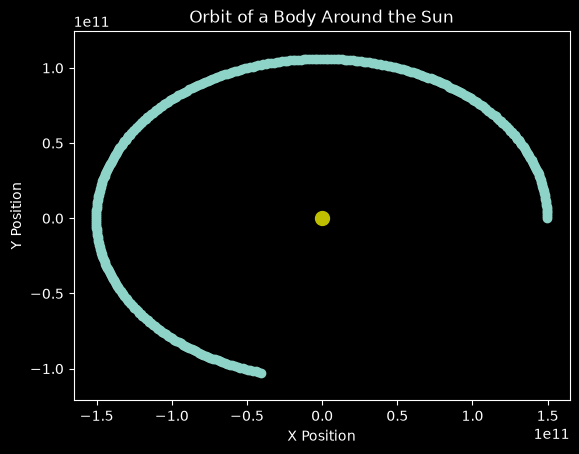

In [40]:
import numpy as np
import matplotlib.pyplot as plt


def next_r(r_k:np.array, v_k:np.array,R:float,dt:float,G:float = 6.67430e-11,M:float = 1.989e30) -> np.array:
    """
    Calculate the next position vector r of a body orbiting the Sun given the following:
    r_k: Current position vector of the body (numpy array)
    v_k: Current velocity vector of the body (numpy array)
    R: Distance from the Sun's centre to the body (float)
    dt: Time step for the simulation, the smaller the more accurate (float)
    G: Gravitational constant (float, default value is 6.67430e-11 m^3 kg^-1 s^-2)
    M: Mass of the Sun (float, default value is 1.989e30 kg)
    """

    next_r = r_k + (dt * v_k) - (0.5 * G * M * R**(-3) * (dt**2)) * r_k

    return next_r

def next_v(r_k:np.array, r_k_plus_1:np.array,v_k:np.array,R:float,dt:float,G:float = 6.67430e-11,M:float = 1.989e30) -> np.array:
    """
    Calculate the next velocity vector v of a body orbiting the Sun given the following:
    r_k: Current position vector of the body (numpy array)
    r_k_plus_1: Next position vector of the body (numpy array)
    v_k: Current velocity vector of the body (numpy array)
    R: Distance from the Sun's centre to the body (float)
    dt: Time step for the simulation, the smaller the more accurate (float)
    G: Gravitational constant (float, default value is 6.67430e-11 m^3 kg^-1 s^-2)
    M: Mass of the Sun (float, default value is 1.989e30 kg)
    """

    next_v = v_k - (G * M * R**(-3)) * (r_k_plus_1 + r_k) * dt

    return next_v

R = 1.496e11  # Distance from the Sun's centre to the body (1 AU in meters)
r_0 = R * np.array([1, 0])  # Initial position vector (1 AU from the Sun)
v_0 = 29.8e3 * np.array([0, 1])  # Initial velocity vector (1e4 m/s)

positions = [r_0]
velocities = [v_0]
for i in range(365): #simulate for a half year)
    r_next = next_r(r_0, v_0, R, dt=60*60*12)  # Update position every day (86400 seconds)
    v_next = next_v(r_0, r_next, v_0, R, dt=60*60*12)  # Update velocity every half-day (43200 seconds)
    #print(f"Day {i+1}: Position = {r_next}, Velocity = {v_next}")
    r_0 = r_next  # Update the current position for the next iteration
    v_0 = v_next  # Update the current velocity for the next iteration
    positions.append(r_next)
    velocities.append(v_next)

# Convert positions to a numpy array for easier plotting
plt.style.use('dark_background')

positions = np.array(positions)
velocities = np.array(velocities)
plt.scatter(positions[:, 0], positions[:, 1])
#plt.scatter(velocities[:, 0], velocities[:, 1], color='r', s=1)  # Plot the velocity vectors in red
plt.plot(0, 0, 'yo', markersize=10)  # Plot the Sun at the origin
plt.axis('equal')
plt.title("Orbit of a Body Around the Sun")
plt.xlabel("X Position")
plt.ylabel("Y Position")
plt.show()